In [ ]:
"Init"

from helper_funcs import *
import helper_funcs
import importlib

importlib.reload(helper_funcs)
import matplotlib.pyplot as plt

plt.rcParams["svg.fonttype"] = "none"
from collections import defaultdict
import numpy as np
import pandas as pd

dirs = get_dirs(root="C:\\Users\\setht\\Dropbox\\Citadel\\GitHub\\otocoherence")
dpi = 1000

In [27]:
fs = 44100
wf_len_s = 60
N = int(fs*wf_len_s)
seed = 0
rng = np.random.default_rng(seed=seed)
gwn = rng.normal(size=N)

pcg = get_params_cgram()

hpf_meth = pcg['hpf_meth']
# hpf_meth = None 

wf_len_s = pcg['wf_len_s']
mode = pcg['mode']
tau_s = pcg['tau_s']
hop_cgram_s = pcg['hop_cgram_s']
hop_psd_s = pcg['hop_psd_s']
nfft_cgram_psd = pcg['nfft']
win_meth_cgram = pcg['win_meth_cgram']
win_type_psd = pcg['win_type_psd']
xi_min_s = pcg['xi_min_s']
delta_xi_s = pcg['delta_xi_s']
T_xi_meth = pcg['T_xi_meth']
T_xi_id = pcg['T_xi_id']
cgram_id = pcg['cgram_id']

beta = pcg['beta']
init_xi_max_s = pcg['init_xi_max_s']

xi_max_s = 0.1

# convert
tau_cgram_psd = int(round(tau_s*fs))
hop_cgram = int(round(hop_cgram_s*fs))
hop_psd = int(round(hop_psd_s*fs))

cgram = load_calc_colossogram(
    **{
        "wf": gwn,
        "wf_idx": seed,
        "wf_fn": f"GWN-{seed}",
        "wf_len_s": wf_len_s,
        "species": "GWN",
        "fs": fs,
        "pkl_folder": dirs["pickles"],
        "mode": mode,
        "tau": tau_cgram_psd,
        "nfft": nfft_cgram_psd, 
        "xi_min_s": xi_min_s,
        "xi_max_s": xi_max_s,
        "hop": hop_cgram,
        "filter_meth": hpf_meth,
        "win_meth": win_meth_cgram,
        "demean": True,
        "const_N_pd": False,
        "scale": False,
    }
)


Using colossogram tau=0.1s with an (asymptotic) hann window, corresponding to an (asymptotic) bandwidth of 15.0 Hz
Processing 'C:\Users\setht\Dropbox\Citadel\GitHub\otocoherence\pickles\GWN 0, mode=phi, rho=1.0, hann, hop=441, tau=4410, HPF=(300Hz cf, 50Hz df, 100dB rip), xi_max=100ms, nfft=None, N_pd=max, DM=True, wf_len=60s, wf=GWN-0 (Colossogram).pkl'


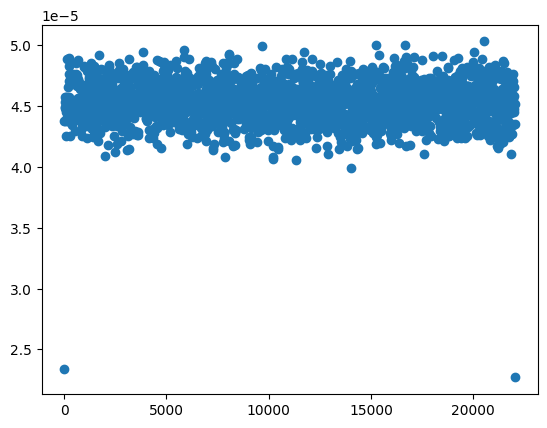

In [28]:
f, psd = pc.get_welch(gwn, fs=fs, tau=int(round(0.1*fs)), hop=int(round(0.05*fs)))
plt.scatter(f, psd)

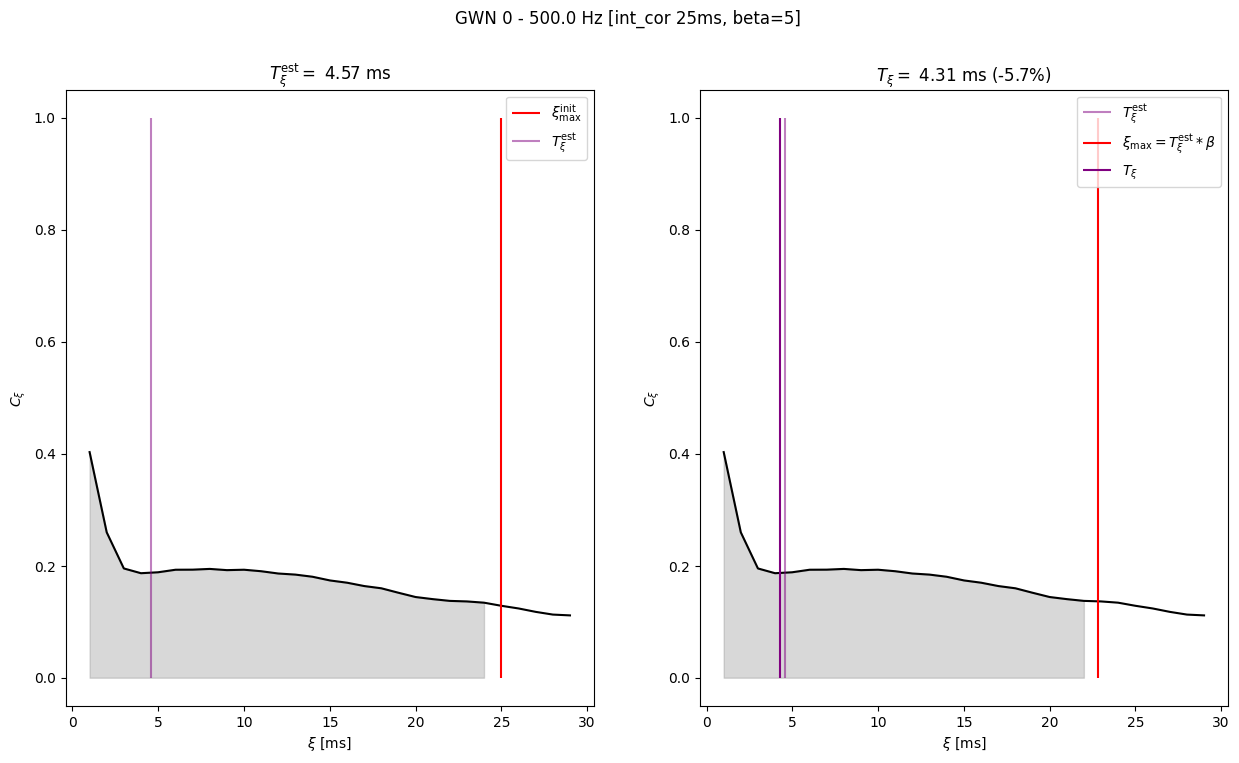

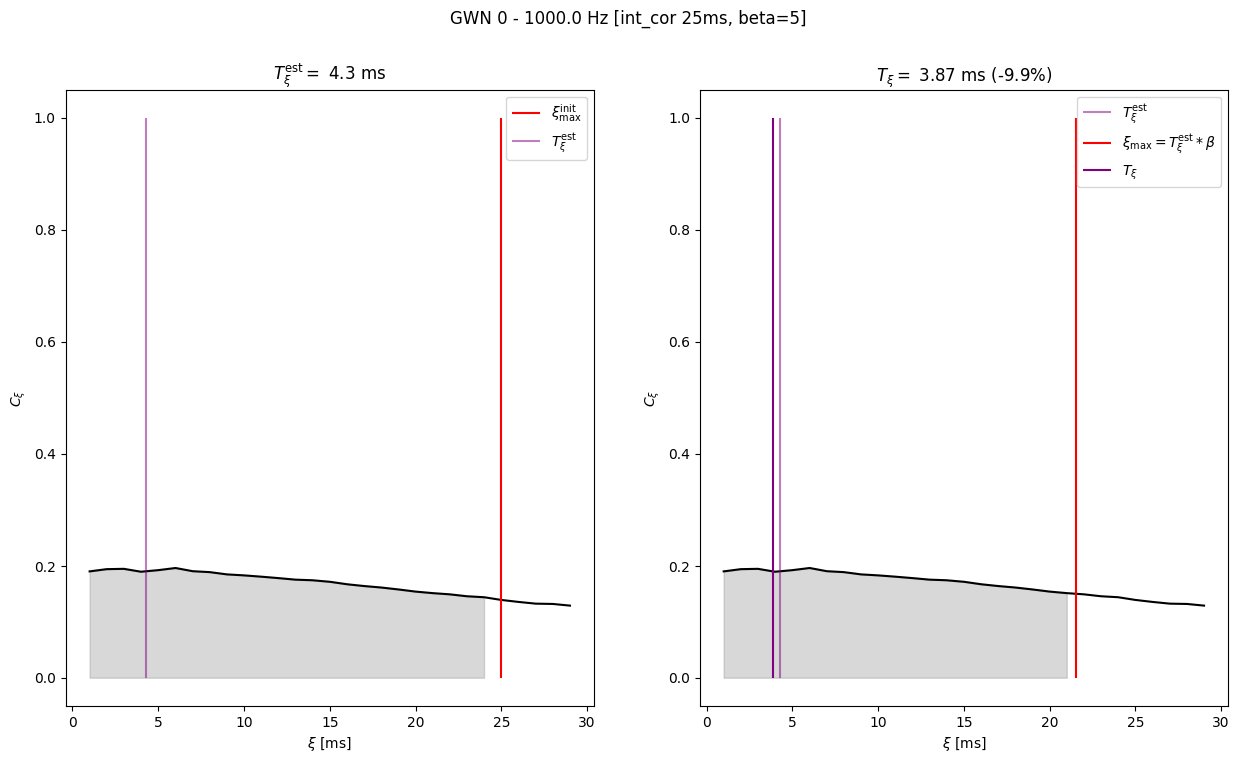

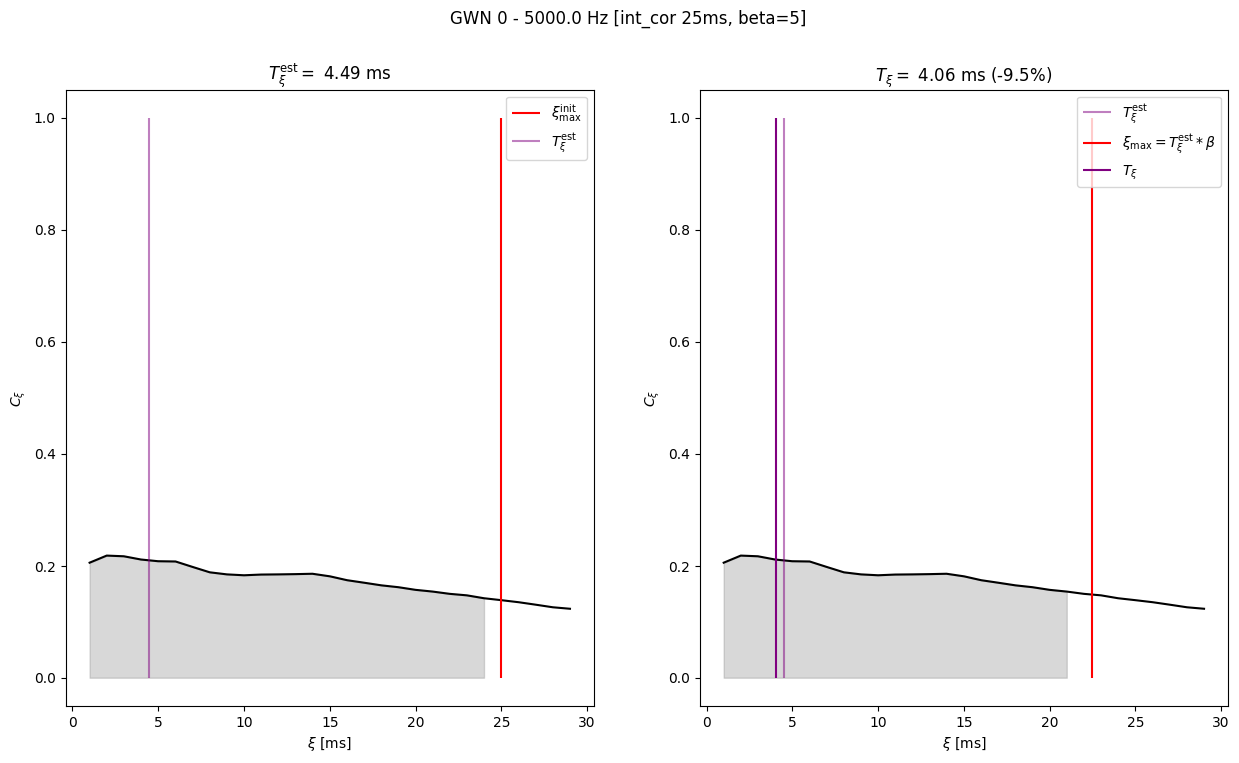

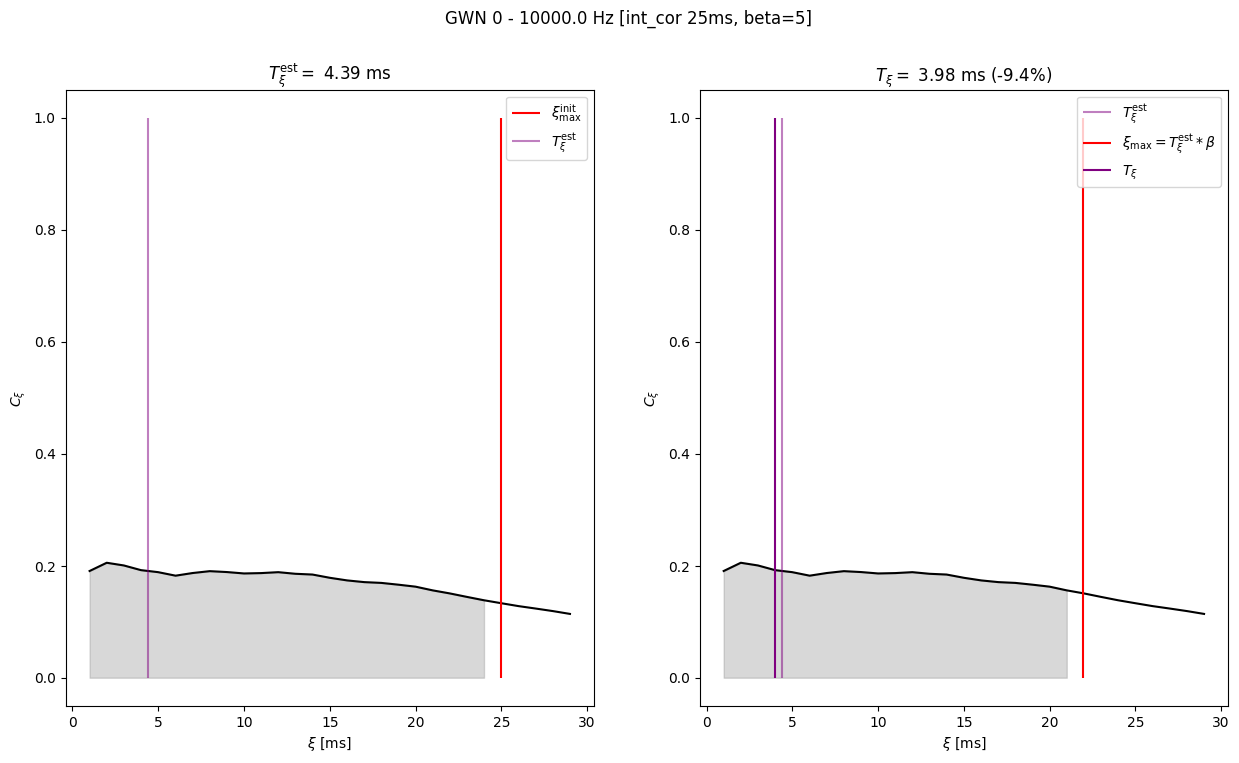

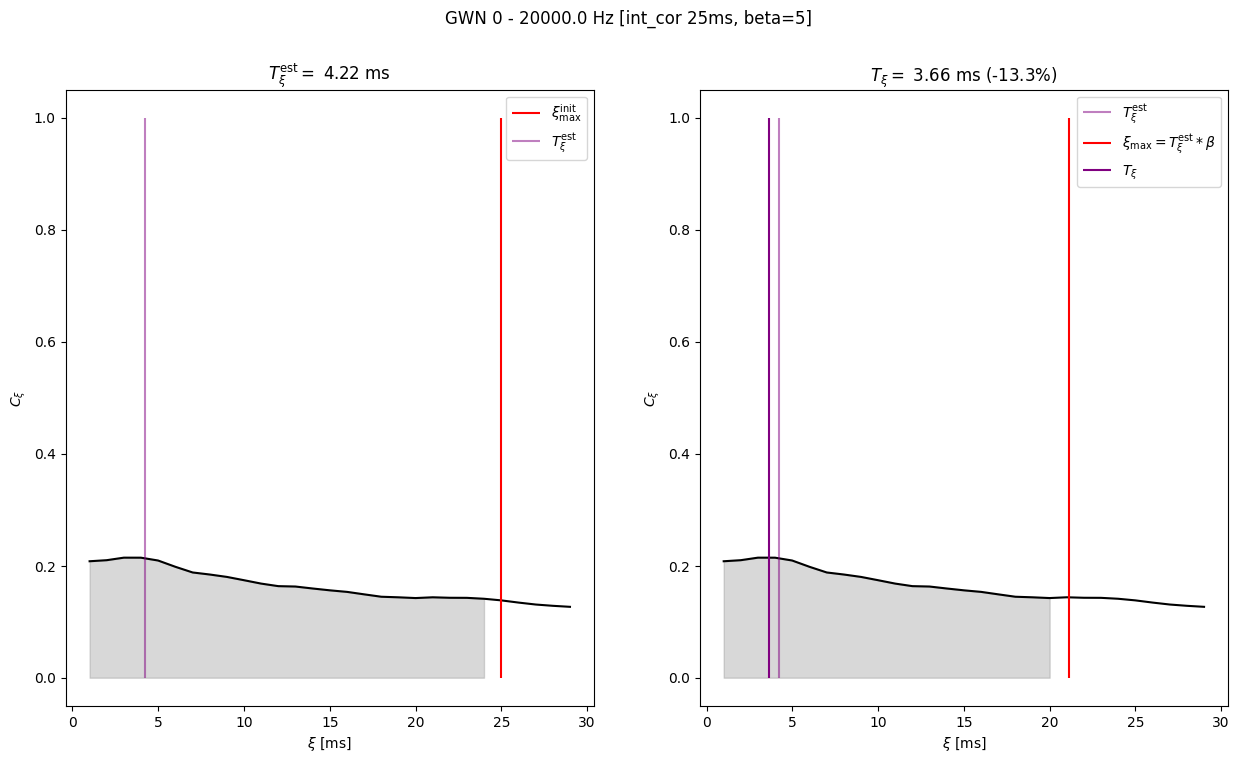

In [29]:
plot=True
f = cgram["f"]
T_xis = np.empty(len(f))
# Identify which frequencies to plot
freqs_plot = np.array([100, 200, 300, 500, 1000, 5000, 10000, 20000])
idxs = np.argmin(np.abs(f[:, None] - freqs_plot[None, :]), axis=0)

for k in range(len(f)):
    if f[k] < pcg['fmin']: # Ignore the lower (filtered) freqs that we ignore in SOAE calcs anyway
        f[k] = np.nan
        continue

    T_xi_phi, T_xi_phi_est = get_T_xi_int_cor(cgram["colossogram"][:, k], cgram["xis_s"], init_xi_max_s, beta)
    T_xis[k] = T_xi_phi

    if plot and (k in idxs):
        # Convert from cgram language to ACF language
        lags_s = cgram['xis_s']
        acf_phi = cgram["colossogram"][:, k]

        # Prep to plot T_xi calculation
        xi_max_s_plot = max([T_xi_phi, init_xi_max_s, T_xi_phi_est * beta]) * 1.2
        lags_max_plot_idx = np.argmin(np.abs(lags_s-xi_max_s_plot))
        lags_ms_plot = lags_s[0:lags_max_plot_idx] * 1000
        acf_phi_plot = acf_phi[0:lags_max_plot_idx]
    
        # Plot
        plt.figure(k, figsize=(15, 8))
        plt.suptitle(f"GWN {seed} - {f[k]:.1f} Hz [{T_xi_id}]")
        
        # Plot the first round
        plt.subplot(1, 2, 1)
        plt.title(rf"$T_\xi^\text{{est}} =$ {T_xi_phi_est*1000:.3g} ms")
        plt.plot(lags_ms_plot, acf_phi_plot, color='k')
        plt.vlines(init_xi_max_s*1000, 0, 1, color='red', label=r'$\xi_\text{max}^\text{init}$')
        idx = np.argmin(np.abs(lags_ms_plot-init_xi_max_s*1000))
        x = lags_ms_plot[0:idx]
        zeros = np.zeros(len(x))
        plt.fill_between(x, zeros, acf_phi_plot[0:idx], color='gray', alpha=0.3)
        plt.vlines(T_xi_phi_est*1000, 0, 1, color='purple', label=r'$T_{\xi}^\text{est}$', alpha=0.5)
        plt.xlabel(r"$\xi$ [ms]")
        plt.ylabel(r"$C_\xi$")
        plt.legend(loc='upper right')

        # Second Round
        plt.subplot(1, 2, 2)
        plt.title(rf"$T_\xi =$ {T_xi_phi*1000:.3g} ms ({100*(T_xi_phi-T_xi_phi_est) / T_xi_phi_est:.1f}%)")
        plt.plot(lags_ms_plot, acf_phi_plot, color='k')
        plt.vlines(T_xi_phi_est*1000, 0, 1, color='purple', label=r'$T_{\xi}^\text{est}$', alpha=0.5)
        plt.vlines(T_xi_phi_est*1000*beta, 0, 1, color='red', label=r'$\xi_\text{max}=T_{\xi}^\text{est}*\beta$')
        idx = np.argmin(np.abs(lags_ms_plot-T_xi_phi_est*1000*beta))
        x = lags_ms_plot[0:idx]
        zeros = np.zeros(len(x))
        plt.fill_between(x, zeros, acf_phi_plot[0:idx], color='grey', alpha=0.3)
        plt.vlines(T_xi_phi*1000, 0, 1, color='purple', label=r'$T_{\xi}$')
        plt.xlabel(r"$\xi$ [ms]")
        plt.ylabel(r"$C_\xi$")
        plt.legend(loc='upper right')

        # Save Fig
        os.makedirs(os.path.join(dirs[f"T_xi_{T_xi_meth}"], f"Cgram {T_xi_id}"), exist_ok=True)
        plt.savefig(os.path.join(dirs[f"T_xi_{T_xi_meth}"], f"Cgram {T_xi_id}", f"GWN {seed} {f[k]:.0f} Hz - ACF [{T_xi_id}, {cgram_id}].jpg"))

In [32]:
mean = np.nanmean(T_xis)
std = np.nanstd(T_xis)
print(rf"GWN: T_xi = {mean:.3g} s +\- {std:.3g} s")

GWN: T_xi = 0.00393 s +\- 0.000658 s
